# From a tax choice to a lending policy

**STATS 201 · Optimization with reinforcement learning**

What happens when a bank makes loans today and then needs cash to meet withdrawals tomorrow? A bank can earn interest by lending. Its cash is also what lets it meet withdrawals and keep lending in later periods. In this tutorial you will **try two rate choices in a published economic simulator, train a banking policy, and judge it on access to credit, earnings, and cash reserves**.

**Start here.** First read the textbook concepts and predict what the bank will do. Then run the code cells from top to bottom in a standard Colab CPU runtime. The saved outputs let you read along before running anything. When you see a Colab form, change one field and rerun that cell to test your reasoning.

**Where this fits.** In the [Week 5 tax exercise](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/08-innovation/week05_matching_ml_methods.ipynb), you learned which tax rate scored better in one round. Now your choice changes what you can do in later rounds.

## 1 · What is reinforcement learning?

In **reinforcement learning (RL)** an **agent**, the decision maker, interacts with an **environment**, the setting that responds to its decisions. It learns a **policy**, a rule for choosing actions, to earn more reward over time. Each interaction gives it an observation, a chance to act, and feedback called a reward. A **reward** is a number that scores an outcome according to a goal you specify. For the textbook account, read chapters 1–3 of [Sutton and Barto, *Reinforcement Learning: An Introduction*, 2nd ed. (MIT Press, 2018)](https://mitpress.mit.edu/9780262039246/reinforcement-learning/).

| Term | What you can picture | Example here |
| --- | --- | --- |
| Agent | Who chooses? | A simulated bank |
| Environment | What responds to the choice? | Borrowing, cash withdrawals, and loan repayments |
| Observation $o_t$ | What can the agent see at decision $t$? | The bank's current cash and demand for loans |
| Action $a_t$ | What can it choose? | A narrow or wide interest-rate spread |
| Reward $r_t$ | What earns or costs points this period? | Interest booked, with a penalty for low cash |
| Policy $\pi(a\mid o)$ | How does it decide? | A probability of choosing each spread given what it sees |
| Episode | What is one complete run? | A 12-period simulation of one bank |

An **interest-rate spread** is the loan interest rate minus the rate paid to depositors. If the bank charges 4.5% on loans and pays 3% on deposits, the spread is **1.5 percentage points**. A **cash reserve** is cash on hand to meet withdrawals or other obligations. **Loan demand** is the total amount borrowers request.

One step in the learning loop is $o_t \rightarrow a_t \rightarrow (r_t, o_{t+1})$. The bank observes, acts, gets its score, and sees the next observation. A learner can **explore** by trying an uncertain action and **exploit** by using the choice that looks best based on what it has learned. Its goal is a high **return**, the sum of current and future rewards with a weight on each future period.

$$
G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \cdots,
\qquad U(\pi)=\mathbb E_\pi[G_0],
\qquad \pi^\star\in\arg\max_\pi U(\pi).
$$

The **discount factor** $\gamma$ is the weight on next period's reward, between 0 and 1 in this tutorial. At $\gamma=0.95$, three successive rewards of 3, 2, and 1 have return $3+0.95(2)+0.95^2(1)=5.8025$. The expectation $\mathbb E_\pi$ averages across episodes generated when following $\pi$. The cheat sheet's $\mathcal A$ is the set of available actions. Here the bank chooses an $a_t\in\mathcal A$ each period, and the objective $U$ scores a whole policy.

**Predict before running.** Two spreads earn the same interest today. One leaves more cash to lend tomorrow. Which has the higher return if new loan requests arrive tomorrow and all other conditions are equal?

## 2 · Two awards and the research question they motivate

- **Computer science.** The **2024 ACM A.M. Turing Award**, announced on **March 5, 2025**, went to **Andrew G. Barto and Richard S. Sutton** for foundational contributions to reinforcement learning. Their work gives us a way to study a decision maker that learns from feedback over time. [ACM award announcement](https://awards.acm.org/binaries/content/assets/press-releases/2025/march/turing-award-2024.pdf)
- **Economics.** The **2025 Sveriges Riksbank Prize in Economic Sciences in Memory of Alfred Nobel** recognized **Joel Mokyr** for work on the prerequisites for sustained growth through technological progress, and **Philippe Aghion and Peter Howitt** for their theory of sustained growth through creative destruction. Creative destruction describes how new technologies and firms displace older ones. Their work motivates a question for fintech research. What financial conditions let new ideas and firms get a chance to grow? [Nobel Prize announcement](https://www.nobelprize.org/uploads/2025/10/press-economicsciencesprize2025.pdf)

**Our question.** How does a simulated bank's rule for pricing loans affect the amount of credit it supplies and the cash it retains, especially during a surge in withdrawals? Think of a lender serving small businesses that need working capital or funds to try a new technology. We will measure aggregate credit supplied and cash held in a simulation. The broader question of which firms get a chance to grow would also need borrower and business outcomes.

## 3 · Try the NeurIPS 2025 EconGym benchmark

Mi and colleagues introduced **EconGym** in the **NeurIPS 2025 Datasets and Benchmarks Track**. A **benchmark** gives researchers a common setting for testing methods. EconGym is a simulator with households, markets, firms, a government, and a commercial bank. Its **optimal bank rate spread** scenario asks how a bank sets its lending and deposit rates alongside central-bank decisions. The original setup initializes households using a processed extract of the **2022 U.S. Survey of Consumer Finances**, a Federal Reserve survey of household finances. The rows we are about to produce are **simulated outcomes**, one summary per bank choice. [Paper and Table 2](https://proceedings.neurips.cc/paper_files/paper/2025/file/40d45b1e23d00d5895e65778e85cf8ee-Paper-Datasets_and_Benchmarks_Track.pdf) · [Bank scenario guide](https://github.com/Miracle1207/EconGym/blob/f0ccbb89869c96ea7058e9539a38c6a637402603/document/Monetary%20Policy%20Issues/Q4-How-to-set-optimal-bank-rate-spreads.md) · [Simulator inputs](https://github.com/Miracle1207/EconGym/tree/f0ccbb89869c96ea7058e9539a38c6a637402603/agents/data) · [Federal Reserve survey](https://www.federalreserve.gov/econres/scfindex.htm)

We will run **one time step in the authors' original simulator**. The paper uses longer runs and trains policies for the bank and central bank. Here we set each actor's action explicitly so that you can trace a single comparison.

| Actor | Its action in this run |
| --- | --- |
| Bank | Loan rate and deposit rate. We compare 4.50% / 3.00% with 6.00% / 2.50%. |
| Central bank | Sets a 3.45% base rate and requires a 10% share of deposits to be held in reserve. |
| Households | Each uses a saving share of 0.20 and a labor fraction of 0.37. |
| Competitive market | Clears trades according to the simulator's rules. |

**First run setup.** Gymnasium provides the simulation interface for our teaching model, Stable-Baselines3 provides the learner, and OmegaConf reads the original benchmark configuration. A package is a reusable set of Python tools. The output lists installed versions for replicating the run.

In [1]:
# Run once in a fresh Colab runtime. Colab already provides PyTorch, NumPy,
# pandas, and Matplotlib. The three pinned packages are used below.
%pip -q install "gymnasium==1.2.3" "stable-baselines3==2.7.1" "omegaconf==2.3.0"

In [2]:
# Standard Python tools for running the published simulator in its own folder.
import json
from importlib.metadata import version
from pathlib import Path
import subprocess
import sys
from tempfile import TemporaryDirectory

# Numerical arrays, readable tables and charts.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Gymnasium defines the environment interface. PPO is the library's learner.
import gymnasium as gym
from gymnasium import spaces
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env

%matplotlib inline
torch.set_num_threads(1)  # A single CPU thread is sufficient for the small model.
pd.set_option("display.max_columns", None)  # Keep every measurement visible.
for package in ["gymnasium", "stable-baselines3", "omegaconf", "torch"]:
    print(f"{package} {version(package)}")

gymnasium 1.2.3
stable-baselines3 2.7.1
omegaconf 2.3.0
torch 2.7.1+cpu


**Before you run EconGym.** Predict which choice earns more bank profit in this particular starting economy. The next cell fetches the authors' public repository at a fixed revision, starts both runs from the same simulated households, and prints the applied rates and two outcomes. **Bank profit** is the simulator's monetary result. **Bank reward** is the score the simulator sends to its bank agent after compressing profit into the range from 0 to 1. Bigger monetary differences can look small on this scale.

**Pseudocode**

1. Download the exact public simulator revision and open the banking scenario.
2. For each candidate spread, reset the economy using the same random seed.
3. Set each actor's action and advance one period.
4. Report the actual rates, profit, and reward side by side.

A **seed** is an integer that recreates a random sequence, so the two bank actions face the same starting economy. The original benchmark needs GitHub access. If the download is unavailable, use the saved output or turn off the form switch and continue to Section 4.

In [3]:
# @title Run the published EconGym bank scenario
run_original_benchmark = True  # @param {type:"boolean"}

repository = "https://github.com/Miracle1207/EconGym.git"
revision = "f0ccbb89869c96ea7058e9539a38c6a637402603"

# This short script runs from the EconGym folder. It imports the authors'
# environment and returns a JSON list of aggregate results (no household rows).
experiment = r'''
import json

import numpy as np
from env.env_core import EconomicSociety
from utils.config import load_config

results = []
for name, lending_rate, deposit_rate in [
    ("Narrow", 0.045, 0.030),
    ("Wide", 0.060, 0.025),
]:
    # Give both policies the same starting economy and households.
    np.random.seed(21)
    config = load_config("optimal_monetary")
    economy = EconomicSociety(config.Environment)
    economy.reset()

    # The central bank holds its base rate and reserve ratio fixed.
    # Each household uses the same saving share and labor fraction in both runs.
    household_count = economy.households.households_n
    actions = {
        "government": {"central_bank": np.array([0.0345, 0.10])},
        "households": np.tile([0.20, 0.37], (household_count, 1)),
        "market": np.array([]),  # The competitive market has no action here.
        "bank": np.array([lending_rate, deposit_rate]),
    }
    # Step the paper's original simulator once. Record the rates actually applied.
    _, rewards, _ = economy.step(actions, t=0)
    bank = economy.bank
    results.append({
        "Rate choice": name,
        "Households": household_count,
        "Loan rate": f"{bank.lending_rate:.2%}",
        "Deposit rate": f"{bank.deposit_rate:.2%}",
        "Spread (percentage points)": 100 * (bank.lending_rate - bank.deposit_rate),
        "Bank profit (model units)": float(np.asarray(bank.profit).item()),
        "Bank reward (scaled)": float(np.asarray(rewards["bank"]).item()),
    })

# Return only aggregate measurements to the notebook.
print(json.dumps(results))
'''

if run_original_benchmark:
    with TemporaryDirectory(prefix="econgym-") as temporary_folder:
        source_folder = Path(temporary_folder)
        # Fetch the reviewed version. The copy is temporary and removed on exit.
        commands = [
            ["git", "init", "--quiet"],
            ["git", "fetch", "--quiet", "--depth=1", repository, revision],
            ["git", "checkout", "--quiet", "--detach", "FETCH_HEAD"],
        ]
        for command in commands:
            subprocess.run(command, cwd=source_folder, check=True, timeout=180)
        checked_out = subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=source_folder, text=True
        ).strip()
        assert checked_out == revision, "The downloaded revision must match the lesson."

        # Running in a separate Python process lets EconGym find its own data
        # files and keeps its random seed local to the benchmark run.
        run = subprocess.run(
            [sys.executable, "-c", experiment],
            cwd=source_folder, capture_output=True, text=True, check=True, timeout=60,
        )
        print(f"EconGym revision {checked_out[:10]} · common starting seed 21")
        results = pd.DataFrame(json.loads(run.stdout))
        # Format the profit for reading without scientific notation.
        readable = results.round(4)
        readable["Bank profit (model units)"] = results["Bank profit (model units)"].map(
            "{:,.0f}".format
        )
        display(readable)
else:
    print("Use the saved benchmark results or continue to Section 4.")

EconGym revision f0ccbb8986 · common starting seed 21


,Rate choice,Households,Loan rate,Deposit rate,Spread (percentage points),Bank profit (model units),Bank reward (scaled)
0,Narrow,100,4.50%,3.00%,1.5,"727,826",0.8834
1,Wide,100,6.00%,2.50%,3.5,"2,270,034",0.8998


**What to notice.** In the saved run, the narrow and wide choices have spreads of **1.5** and **3.5 percentage points**. With these actors' decisions held fixed for one step, wide produces more modeled profit. Reward moves by much less because of its scale. We have learned a comparison for this starting state. To evaluate a policy, we also need to see how its choices change tomorrow's situation and how it does over many periods.

**Connect to your research.** If you were studying access to loans for early-stage green businesses, what borrower information would you add to learn **who** was able to borrow?

## 4 · Build the classroom lending environment

EconGym has several actors and many moving parts. We now model **one bank and two actions** so that we can calculate one step by hand and then watch a learning algorithm make the same decision repeatedly. The numbers below are **teaching assumptions**. A **withdrawal shock** is an unusually large withdrawal. In our example it removes 22% of cash after repayments in periods 5 and 6, compared with 3% each period in the calm scenario.

The **state** is the simulator's full situation, including the withdrawal scenario. The agent's **observation** contains what the bank sees when choosing. Two episodes can begin with the same observation and produce different paths after a shock.

| Cheat-sheet role | Classroom meaning | Python |
| --- | --- | --- |
| Observation $o_t$ | Cash $c_t$, repayment $b_t$ due after today's lending decision, requests $d_t$, and elapsed time $t$ | Four numbers in the array from `reset()` or `step()` |
| Feasible actions $\mathcal A$ | 0 for narrow and 1 for wide | `spaces.Discrete(2)` |
| Chosen action $a_t$ | A spread choice for this period | `action` |
| Reward $r_t$ | Net interest booked minus a penalty for a cash shortfall | `reward` |
| Objective $U(\pi)$ | Average discounted return of following the policy | Estimated in Section 6 |

Each action has an **acceptance fraction** $\alpha_a$ and a **net interest margin** $m_a$. In the model the narrow spread attracts more borrowing at a lower margin, and the wide spread attracts less borrowing at a higher margin. Net interest here is a modeled margin on funded loans, recorded when the loan is made.

| Action | Fraction $\alpha_a$ | Margin $m_a$ |
| --- | ---: | ---: |
| 0 · Narrow | 0.80 | 0.04 |
| 1 · Wide | 0.45 | 0.06 |

### From the formula to one bank decision

Let $L_t$ be the amount lent, $C_t$ cash immediately after lending, $I_t$ net interest booked, and $S_t$ the amount that cash falls below target $B=25$. Cash and amounts in this model are in simulated credits. The reward penalty $\lambda=0.20$ is reward credits per credit of cash shortfall.

$$
L_t=\min(c_t,\alpha_{a_t}d_t),\qquad C_t=c_t-L_t,\qquad I_t=m_{a_t}L_t,
\qquad S_t=\max(0,B-C_t),\qquad r_t=I_t-\lambda S_t.
$$

Add any repayment $b_t$ due after the decision, apply withdrawal share $w_t$, and carry today's loan and its interest forward for repayment at the end of the next period.

$$
c_{t+1}=(C_t+b_t)(1-w_t),\qquad b_{t+1}=L_t+I_t.
$$

**Work it out first.** With 60 cash and 50 requested, narrow lends $\min(60,0.8\times50)=40$, leaving $20$ cash. It books $1.60$ interest, falls $5$ below the reserve target, and earns $1.60-0.20(5)=0.60$. Calculate the wide-spread reward before checking the table.

**Pseudocode**

1. Reset to starting cash and draw 12 periods of loan requests.
2. Compute lending, interest, cash shortfall, and reward using the chosen action.
3. Apply repayments and withdrawals, then build the next observation.
4. Repeat until all 12 periods are complete.

**Before running.** The following cell defines the classroom rules and uses Gymnasium's observation and action spaces. `reset()` starts a run. `step(action)` advances it. `check_env` checks that return values follow the Gymnasium interface so the RL package can use it.

In [4]:
class LendingEnv(gym.Env):
    """One bank repeatedly chooses a rate spread over a 12-period episode."""

    def __init__(self, scenario="mixed"):
        super().__init__()
        self.scenario = scenario
        self.horizon = 12
        self.reserve_target = 25.0
        self.reserve_weight = 0.20
        self.action_space = spaces.Discrete(2)  # 0 = narrow spread, 1 = wide spread
        # Scale money columns by 100 and elapsed periods by 12 for the learner.
        self.observation_space = spaces.Box(
            low=0.0, high=2.0, shape=(4,), dtype=np.float32
        )

    def _observation(self):
        # Demand is zero in the final observation because the episode is over.
        demand = self.demands[self.period] if self.period < self.horizon else 0.0
        return np.array(
            [self.cash / 100, self.repayment_due / 100, demand / 100,
             self.period / self.horizon],
            dtype=np.float32,
        )

    def reset(self, *, seed=None, options=None):
        # Gymnasium gives us a reproducible random number generator for each seed.
        super().reset(seed=seed)
        self.period = 0
        self.cash = 60.0
        self.repayment_due = 0.0
        self.demands = self.np_random.choice([35.0, 50.0, 65.0], size=self.horizon)
        if options and "first_demand" in options:
            self.demands[0] = options["first_demand"]
        # Training sees both scenarios. Evaluation can fix the scenario.
        self.active_scenario = self.scenario
        if self.scenario == "mixed":
            self.active_scenario = self.np_random.choice(["calm", "withdrawal shock"])
        return self._observation(), {}

    def step(self, action):
        # Use the bank's current cash and demand to calculate today's lending.
        acceptance, spread = [(0.80, 0.04), (0.45, 0.06)][int(action)]
        funded = min(self.cash, acceptance * self.demands[self.period])
        cash_after_lending = self.cash - funded
        interest = funded * spread
        reserve_gap = max(0.0, self.reserve_target - cash_after_lending)
        reward = interest - self.reserve_weight * reserve_gap

        # A repayment due today arrives after the lending decision. New loans
        # become due at the end of the next period and fund the decision after that.
        withdrawal_share = 0.03
        if self.active_scenario == "withdrawal shock" and self.period in (4, 5):
            withdrawal_share = 0.22  # Periods 5 and 6 on the student-facing chart.
        self.cash = (cash_after_lending + self.repayment_due) * (1 - withdrawal_share)
        self.repayment_due = funded + interest
        self.period += 1

        # Return teaching metrics separately from the four values the agent sees.
        info = {
            "Period": self.period,
            "Action": "Narrow" if int(action) == 0 else "Wide",
            "Funded volume": funded,
            "Cash after lending": cash_after_lending,
            "Net interest booked": interest,
            "Reserve shortfall": reserve_gap,
            "Withdrawal share": withdrawal_share,
            "Reward": reward,
        }
        terminated = self.period == self.horizon
        truncated = False  # There is no external time cutoff in this exercise.
        return self._observation(), float(reward), terminated, truncated, info


# The library checks the range, shape, data type, and return values.
check_env(LendingEnv(), skip_render_check=True)
print("Checked Gymnasium interface: four observation values and two actions.")

Checked Gymnasium interface: four observation values and two actions.


**Try the hand calculation.** The next cell resets the bank twice to the same starting situation. Change **requested credit** and rerun the cell. Compare the change in lending, net interest, reserve shortfall, and reward. Which column explains a change in the preferred action?

In [5]:
# @title Compare two actions from the same starting point
requested_credit = 50  # @param {type:"slider", min:35, max:65, step:5}

# Reset before each action so both rows start with 60 cash and the same demand.
examples = []
for action in (0, 1):
    example_bank = LendingEnv(scenario="calm")
    example_bank.reset(seed=7, options={"first_demand": requested_credit})
    # We use the info dictionary, which holds the named measurements.
    _, _, _, _, outcome = example_bank.step(action)
    examples.append(outcome)
display(pd.DataFrame(examples)[[
    "Action", "Funded volume", "Cash after lending", "Net interest booked",
    "Reserve shortfall", "Reward",
]].round(2))

,Action,Funded volume,Cash after lending,Net interest booked,Reserve shortfall,Reward
0,Narrow,40.0,20.0,1.60,5.0,0.60
1,Wide,22.5,37.5,1.35,0.0,1.35


**What to notice.** At a request of 50, wide earns **1.35** in reward and lends **22.5**, while narrow earns **0.60** and lends **40**. At a request of 35, narrow earns **1.12** and beats wide's **0.945** reward. The amount requested matters because an identical choice can leave different amounts of cash. A policy can respond differently to different observations.

## 5 · Learn a policy using Stable-Baselines3 PPO

The Week 5 tax exercise uses a **multi-armed bandit**, a way to learn between actions when each round is scored on its own. Today's action in the bank changes tomorrow's cash and the choices that are practical later. Use **Proximal Policy Optimization (PPO)**, an RL algorithm for learning a policy from sequences of experience. We call the implementation directly from [Stable-Baselines3](https://stable-baselines3.readthedocs.io/en/v2.7.1/modules/ppo.html).

PPO has two learned parts. The **policy** chooses what to do. A **value function** estimates how much return the bank can earn from a given observation. PPO uses those estimates to decide which sampled actions worked better than expected, and limits the incentive for very large changes in action probability during an update.

**Pseudocode**

1. Start with a policy that sometimes chooses each action.
2. Use the policy in the bank simulator and record observations, actions, and rewards.
3. Estimate the return and how each sampled action did relative to expectations.
4. Adjust the policy and value estimates with PPO. Repeat until the training budget is used up.

<details>
<summary>Optional math · the policy update</summary>

Schulman et al. (2017) give the following clipped objective for the policy part of PPO.

$$
\rho_t(\theta)=\frac{\pi_\theta(a_t\mid o_t)}{\pi_{\theta_{\rm old}}(a_t\mid o_t)},\qquad
L^{\rm CLIP}(\theta)=\widehat{\mathbb E}_t
\left[\min\left(\rho_t(\theta)\widehat A_t,\,
\operatorname{clip}(\rho_t(\theta),1-\epsilon,1+\epsilon)\widehat A_t\right)\right].
$$

$\theta$ are policy parameters. $\rho_t$ compares the new and old probabilities of the action taken. The **advantage** $\widehat A_t$ estimates how much better the action did than expected. The clip parameter $\epsilon$ gives the range $[1-\epsilon,1+\epsilon]$ used to form the second term. The sample average $\widehat{\mathbb E}_t$ is over recorded training steps. Stable-Baselines3 also trains the value estimate and manages collection and updating. [Schulman et al., *Proximal Policy Optimization Algorithms*](https://arxiv.org/abs/1707.06347)

</details>

**Before training.** We give PPO mixed calm and shock practice runs. `total_timesteps` counts simulated bank decisions for training. Anticipate about 8,000 decisions. The output tells you how many the library actually used, because PPO collects experience in batches. The next section measures how the fitted policy generalizes to fresh scenarios.

In [6]:
# The training environment varies loan requests and selects calm or shock cases.
train_bank = LendingEnv(scenario="mixed")
discount = 0.95

# MlpPolicy uses a small neural network, a flexible function with fitted weights.
# PPO handles finding those weights. The seed makes this run repeatable on CPU.
# It collects 96 decisions before each update, uses 48 records per batch,
# and makes four passes through those decisions. The learning rate sets
# the update scale.
model = PPO(
    "MlpPolicy", train_bank, gamma=discount, seed=2025, device="cpu",
    n_steps=96, batch_size=48, n_epochs=4, learning_rate=0.0003,
    policy_kwargs={"net_arch": [32, 32]}, verbose=0,
)
model.learn(total_timesteps=8_000)
print(f"PPO collected {model.num_timesteps:,} training decisions.")

PPO collected 8,064 training decisions.


## 6 · Test the learned policy and compare the trade-offs

A **baseline** is a simple reference policy that helps us judge the learned one. We use two. **Always narrow** always selects action 0. **Reserve rule** switches to wide if lending with narrow would take cash below 25. PPO chooses the action it assigns the highest probability at each observation during testing.

Before seeing the results, choose which of these outcomes would be most important for your project.

| Reported metric | How it is calculated for each episode | How to read it |
| --- | --- | --- |
| Discounted return | Sum of step rewards, weighted by $0.95^t$ | Higher fits the goal we gave PPO |
| Funded volume | Add the amount lent over the 12 periods | Higher means more credit supplied, in credits |
| Net interest | Add the interest booked across periods | Higher means more booked interest, in credits |
| Total reserve shortfall | Add the amounts below the cash target after lending | Lower means fewer or smaller reserve gaps, in credit-periods |

**Before evaluating.** We test each policy on eight new demand sequences in the calm setting and the same eight in the shock setting. Reusing each test seed across policies gives them equal starting cash and requests. These **held-out** episodes use seeds reserved for testing. The code records what happens at each step and then averages the episode totals.

**Pseudocode**

1. Reset to a test seed and scenario.
2. Run each policy on that setup and record its 12 outcomes.
3. Calculate every metric using the same definitions for the three policies.
4. Average by scenario and compare. Which metric changes most during the shock?

In [7]:
policy_names = ["Always narrow", "Reserve rule", "PPO"]
test_scenarios = ["calm", "withdrawal shock"]
test_seeds = range(100, 108)


def run_episode(policy, scenario, seed):
    # Apply one policy to one fixed test case and save each period's results.
    bank = LendingEnv(scenario=scenario)
    observation, _ = bank.reset(seed=seed)
    rows = []
    for _ in range(bank.horizon):
        if policy == "Always narrow":
            action = 0
        elif policy == "Reserve rule":
            # Convert the observation's normalized cash and demand to credits.
            cash, _, demand, _ = 100 * observation
            action = int(cash - min(cash, 0.80 * demand) < bank.reserve_target)
        else:
            choice, _ = model.predict(observation, deterministic=True)
            action = int(np.asarray(choice).item())
        observation, _, terminated, truncated, info = bank.step(action)
        rows.append(info)
        if terminated or truncated:
            break
    return pd.DataFrame(rows)


episode_results = []
for scenario in test_scenarios:
    for seed in test_seeds:
        for policy in policy_names:
            trace = run_episode(policy, scenario, seed)
            # The first reward has exponent 0, the second exponent 1, and so on.
            weights = discount ** np.arange(len(trace))
            episode_results.append({
                "Scenario": scenario,
                "Policy": policy,
                "Discounted return": np.dot(weights, trace["Reward"]),
                "Funded volume": trace["Funded volume"].sum(),
                "Net interest": trace["Net interest booked"].sum(),
                "Total reserve shortfall": trace["Reserve shortfall"].sum(),
            })

episodes = pd.DataFrame(episode_results)
average_results = episodes.groupby(["Scenario", "Policy"], sort=False).mean()
print("Mean per episode · 8 common held-out demand sequences per scenario")
display(average_results.round(2))

Mean per episode · 8 common held-out demand sequences per scenario


Discounted return  Funded volume  \
Scenario         Policy                                            
calm             Always narrow             -28.00         355.09   
                 Reserve rule               -4.38         266.16   
                 PPO                        -3.84         261.56   
withdrawal shock Always narrow             -30.26         319.94   
                 Reserve rule              -13.95         260.77   
                 PPO                       -13.36         256.07   

                                Net interest  Total reserve shortfall  
Scenario         Policy                                                
calm             Always narrow         14.20                   259.71  
                 Reserve rule          15.76                   107.21  
                 PPO                   15.69                   104.44  
withdrawal shock Always narrow         12.80                   269.71  
                 Reserve rule          15.44                   177.66  
                 PPO                   15.36                   174.40

**Read across the columns.** In the saved shock runs, PPO averages **−13.36** on discounted return and the reserve rule averages **−13.95**. The negative returns mean cash-shortfall penalties outweigh the interest in the discounted sum. PPO gains about **0.59** on that score while the reserve rule funds about **4.7 more credits**. Always narrow funds the most and has the largest shortfall. The ranking depends on the outcome you want to improve. These are averages of eight simulated episodes per setting, so check how stable the differences are before drawing a conclusion.

**Look at one run.** Use the next control to see **cash immediately after lending** for each policy. A point below the dashed line means a shortfall that period. The shaded area marks when unusually large withdrawals occur **after** each lending decision. Look in the following period for their effect. Overlapping lines show that policies leave the same amount of cash. Try seed **100** after the default run and look for how closely PPO and the reserve rule track each other.

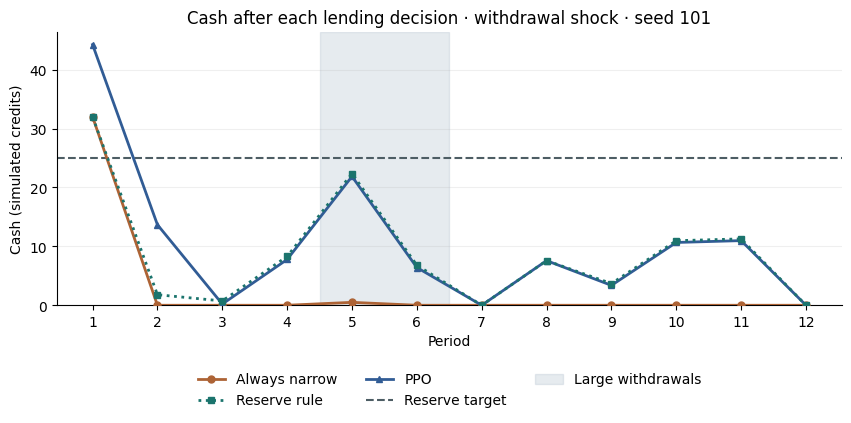

In [8]:
# @title Inspect a held-out bank episode
scenario = "withdrawal shock"  # @param ["calm", "withdrawal shock"]
seed = 101  # @param {type:"slider", min:100, max:107, step:1}

# The same scenario and seed recreate the same borrower requests for all policies.
fig, ax = plt.subplots(figsize=(8.4, 4.1), layout="constrained")
colors = ["#AD6335", "#1B746D", "#315C95"]
markers = ["o", "s", "^"]
for policy, color, marker in zip(policy_names, colors, markers):
    trace = run_episode(policy, scenario, seed)
    ax.plot(
        trace["Period"], trace["Cash after lending"],
        label=policy, color=color, marker=marker, linewidth=2, markersize=5,
        linestyle=":" if policy == "Reserve rule" else "-",
        zorder=4 if policy == "Reserve rule" else 3,
    )

ax.axhline(25, color="#4D5D64", linestyle="--", label="Reserve target")
if scenario == "withdrawal shock":
    ax.axvspan(4.5, 6.5, color="#A8B8C7", alpha=0.28, label="Large withdrawals")
ax.set(
    title=f"Cash after each lending decision · {scenario} · seed {seed}",
    xlabel="Period", ylabel="Cash (simulated credits)", xticks=range(1, 13), ylim=(0, None),
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.20)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3, frameon=False)
plt.show()

### Revise the design

**A first research revision.** Suppose your main question is whether small green businesses receive credit. Funded volume can rise while a small group of borrowers receives most of it. You could add borrower type to the simulation and report the share of requests funded for each group. Keep the common test scenarios and check whether a policy that appears strong on overall return also serves the group you care about.

**What the evidence supports.** These runs show how policies behave under explicit assumptions about interest, repayments, and withdrawals. A claim about real fintech lending would require evidence about borrower responses, defaults, and withdrawals. To test whether a finding depends on our assumptions, try another set of test seeds and change how loan demand responds to spreads. Assess whether the ranking survives.

**Apply it to your project.** Who takes an action in your setting? Which outcome could this action change later? Name one measure of success you would report alongside reward and one new test situation that might change your conclusion.

## 7 · Which Python package does what?

| Role | Package and when to use it | Start with |
| --- | --- | --- |
| Environment · the rules of the world | **Gymnasium** is the maintained successor to OpenAI Gym. Use it to make one decision maker's observations, actions, and feedback readable by an RL library. | `Env`, `reset`, `step`, `spaces`. [Gymnasium API](https://gymnasium.farama.org/api/env/) |
| Multi-agent environment · several decision makers | **PettingZoo** defines how multiple agents take turns or act at once. Think of a bank and a central bank choosing together. | Read the [Parallel API](https://pettingzoo.farama.org/api/parallel/) for simultaneous actions. |
| Bandit learner · each round is scored on its own | **MABWiser** fits bandit rules. Use it for the one-round tax lesson. | [MABWiser documentation](https://fidelity.github.io/mabwiser/) · [Week 5 tax exercise](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/08-innovation/week05_matching_ml_methods.ipynb) |
| RL agent · choices affect later periods | **Stable-Baselines3** fits sequential policies. This tutorial uses PPO. **Deep Q-Network (DQN)** is another option for a finite set of actions. It estimates the expected return for each action. | [PPO](https://stable-baselines3.readthedocs.io/en/v2.7.1/modules/ppo.html) · [DQN](https://stable-baselines3.readthedocs.io/en/v2.7.1/modules/dqn.html) |
| Integrated training · train interacting agents or scale experiments | **Ray RLlib** handles training with several interacting policies. **TorchRL** provides tools to collect experience, transform it, and train policies with PyTorch. | [RLlib multi-agent environments](https://docs.ray.io/en/latest/rllib/multi-agent-envs.html) · [TorchRL documentation](https://docs.pytorch.org/rl/stable/index.html) |
| Benchmark · compare experiments in the same economy | **EconGym** provides published economic scenarios, measurements, and training configurations. | [EconGym code and scenario index](https://github.com/Miracle1207/EconGym/tree/f0ccbb89869c96ea7058e9539a38c6a637402603) |

For a bank and a central bank that both learn, begin by defining who can see what, when each can act, and what reward each receives. Those design choices tell you whether a multi-agent environment and trainer are useful.

## Glossary

| Term or symbol | Meaning in this tutorial |
| --- | --- |
| Agent, environment | The decision maker and the setting that responds to its actions |
| State, observation $o_t$ | The state is the environment's full situation. An observation is the part the agent sees, such as today's requests. |
| Feasible actions $\mathcal A$, action $a_t$ | The two options the classroom bank has and which one it takes at period $t$ |
| Policy $\pi(a\mid o)$ | A rule for choosing an action from an observation |
| Transition, episode | One step from a decision to its consequences, and one complete run of steps |
| Exploration, exploitation | Trying a choice to learn about it, and using the choice that looks best so far |
| Reward $r_t$, return $G_t$, objective $U(\pi)$ | Score for one step, discounted sum of scores starting at $t$, and expected return from the start |
| Discount factor $\gamma$ | How much next period's reward is worth relative to this period's reward |
| Value estimate, advantage $\widehat A_t$ | Estimated return from an observation, and how much better an action did than expected |
| Benchmark, baseline | A shared test setting, and a reference method to compare against |
| Seed, held-out episode | An integer that recreates a random sequence, and a separate episode used for evaluation |
| Spread, percentage point | The lending rate minus the deposit rate, and the unit for a difference between percentages |
| Loan demand $d_t$, funded volume $L_t$ | Credits requested, and credits the bank actually lends |
| Cash $c_t$, repayment due $b_t$, after-lending cash $C_t$ | Cash before today's decision, repayment arriving after it, and cash left immediately after lending |
| Acceptance $\alpha_a$, margin $m_a$, interest $I_t$ | Fraction of credit requests that take up the offer, interest earned per funded credit, and total net interest booked |
| Reserve target $B$, shortfall $S_t$, penalty $\lambda$ | Desired cash after lending, credits below that target, and the reward cost of a credit of shortfall |
| Withdrawal share $w_t$, shock | The fraction of cash withdrawn after repayments, and a period of unusually large withdrawals |

## References

- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. [Textbook](https://mitpress.mit.edu/9780262039246/reinforcement-learning/)
- Association for Computing Machinery. (2025, March 5). *ACM A.M. Turing Award honors two researchers who led the development of cornerstone AI technology*. [Official announcement](https://awards.acm.org/binaries/content/assets/press-releases/2025/march/turing-award-2024.pdf)
- Royal Swedish Academy of Sciences. (2025, October 13). *The Prize in Economic Sciences 2025*. [Official announcement](https://www.nobelprize.org/uploads/2025/10/press-economicsciencesprize2025.pdf)
- Mi, Q., Yang, Q., Fan, Z., Fan, W., Ma, H., Ma, C., Xia, S., An, B., Wang, J., & Zhang, H. (2025). EconGym: A scalable AI testbed with diverse economic tasks. *Advances in Neural Information Processing Systems, 38*, Datasets and Benchmarks Track. [Proceedings](https://doi.org/10.52202/085713-1515) · [Original banking scenario and code](https://github.com/Miracle1207/EconGym/tree/f0ccbb89869c96ea7058e9539a38c6a637402603)
- Board of Governors of the Federal Reserve System. (2023). *2022 Survey of Consumer Finances*. [Survey documentation and data](https://www.federalreserve.gov/econres/scfindex.htm)
- Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O. (2017). Proximal policy optimization algorithms. *arXiv:1707.06347*. [Paper](https://arxiv.org/abs/1707.06347)
- Zheng, S., Trott, A., Srinivasa, S., Parkes, D. C., & Socher, R. (2022). The AI Economist: Taxation policy design via two-level deep multiagent reinforcement learning. *Science Advances, 8*(18), eabk2607. [Paper](https://doi.org/10.1126/sciadv.abk2607)